Note: you may need to restart the kernel to use updated packages.
Quantum Teleportation Circuit:
     ┌───┐ ░            ░      ┌───┐ ░ ┌─┐            ░    
q_0: ┤ X ├─░────────────░───■──┤ H ├─░─┤M├─────────■──░────
     └───┘ ░ ┌───┐      ░ ┌─┴─┐└───┘ ░ └╥┘┌─┐      │  ░    
q_1: ──────░─┤ H ├──■───░─┤ X ├──────░──╫─┤M├──■───┼──░────
           ░ └───┘┌─┴─┐ ░ └───┘      ░  ║ └╥┘┌─┴─┐ │  ░ ┌─┐
q_2: ──────░──────┤ X ├─░────────────░──╫──╫─┤ X ├─■──░─┤M├
           ░      └───┘ ░            ░  ║  ║ └───┘    ░ └╥┘
c: 3/═══════════════════════════════════╩══╩═════════════╩═
                                        0  1             2 

Teleported State Results:
{'100': 252, '111': 245, '101': 217, '110': 286}


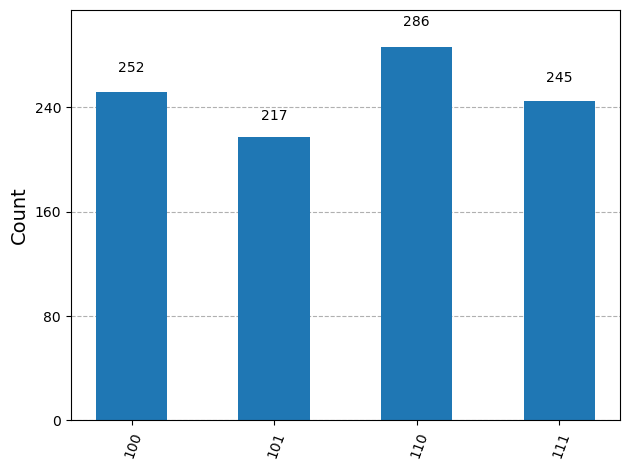

In [2]:

# Install required libraries
%pip install qiskit qiskit-aer matplotlib

# Import libraries
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram

# Step 1: Create a quantum circuit with 3 qubits and 3 classical bits
circuit = QuantumCircuit(3, 3)

# Step 2: Prepare the initial state to be teleported
# Apply X gate to q0 to prepare state |1>
circuit.x(0)
circuit.barrier()

# Step 3: Create entanglement between q1 and q2
circuit.h(1)
circuit.cx(1, 2)
circuit.barrier()

# Step 4: Apply CNOT between q0 and q1
circuit.cx(0, 1)

# Apply Hadamard gate to q0
circuit.h(0)
circuit.barrier()

# Step 5: Measure Alice's two qubits
circuit.measure(0, 0)
circuit.measure(1, 1)

# Step 6: Apply correction operations on Bob's qubit
# Controlled-X operation
circuit.cx(1, 2)

# Controlled-Z operation
circuit.cz(0, 2)
circuit.barrier()

# Step 7: Measure the teleported qubit
circuit.measure(2, 2)

# Step 8: Display the quantum circuit
print("Quantum Teleportation Circuit:")
print(circuit.draw(fold=120))

# Step 9: Simulate the circuit
simulator = AerSimulator()

compiled_circuit = transpile(circuit, simulator)

result = simulator.run(
    compiled_circuit,
    shots=1000
).result()

# Step 10: Get and display the results
counts = result.get_counts()

print("\nTeleported State Results:")
print(counts)

# Step 11: Display histogram
plot_histogram(counts)



# Practical 4: Oral Questions and Answers

**Practical Name:** Implement Quantum Teleportation Algorithm in Python.

## 1. Basic Questions

**Q1. What is Quantum Teleportation?**

Quantum Teleportation is a process of transferring a quantum state from one qubit to another using entanglement and classical communication.

**Q2. What is the aim of this practical?**

To understand the Quantum Teleportation algorithm, create a quantum circuit and perform entanglement using Qiskit.

**Q3. What is a qubit?**

A qubit is the basic unit of quantum information. It can exist in a combination of 0 and 1 states.

**Q4. What is entanglement?**

Entanglement is a quantum phenomenon in which two or more qubits become connected, so their states are correlated.

**Q5. What is the no-cloning theorem?**

The no-cloning theorem states that an unknown quantum state cannot be copied perfectly.

**Q6. Why is Quantum Teleportation needed?**

It allows the transfer of an unknown quantum state without directly copying it.

**Q7. Does Quantum Teleportation transfer physical particles?**

No. It transfers the quantum state, not the physical particle.

**Q8. How many qubits are used in this practical?**

Three qubits are used.

**Q9. How many classical bits are used?**

Three classical bits are used in our circuit.

**Q10. Who are Alice and Bob in Quantum Teleportation?**

Alice is the sender, and Bob is the receiver of the quantum state.

## 2. Quantum Gates

**Q11. Which gates are used in Quantum Teleportation?**

X gate, Hadamard gate, CNOT gate and CZ gate.

**Q12. What is an X gate?**

An X gate flips the qubit state from 0 to 1 or from 1 to 0.

**Q13. What is a Hadamard gate?**

A Hadamard gate creates superposition from a computational basis state.

**Q14. What is a CNOT gate?**

A CNOT gate flips the target qubit when the control qubit is 1.

**Q15. What is a CZ gate?**

A Controlled-Z gate applies a Z operation to the target qubit when the control qubit is 1.

**Q16. What is a Z gate?**

A Z gate changes the phase of the |1> state while keeping the |0> state unchanged.

**Q17. What is a Bell pair?**

A Bell pair is a pair of maximally entangled qubits.

**Q18. How is entanglement created in this practical?**

By applying a Hadamard gate to q1 followed by a CNOT gate between q1 and q2.

## 3. Circuit-Based Questions

**Q19. What does QuantumCircuit(3, 3) mean?**

It creates a quantum circuit with 3 qubits and 3 classical bits.

**Q20. Why is an X gate applied to q0?**

To prepare the initial state |1> that we want to teleport.

**Q21. What is the purpose of circuit.barrier()?**

It separates different circuit operations and makes the circuit easier to understand.

**Q22. What is the purpose of circuit.h(1)?**

It applies a Hadamard gate to the second qubit.

**Q23. What is the purpose of circuit.cx(1, 2)?**

It creates entanglement between q1 and q2.

**Q24. Why is circuit.cx(0, 1) applied?**

It connects the qubit to be teleported with Alice's entangled qubit.

**Q25. Why is a Hadamard gate applied to q0?**

It helps prepare the circuit for Alice's Bell-basis measurement.

**Q26. Why do we measure q0 and q1?**

To obtain Alice's measurement results, which determine the correction operations.

**Q27. What is the purpose of circuit.cx(1, 2)?**

It applies the controlled-X correction to Bob's qubit.

**Q28. What is the purpose of circuit.cz(0, 2)?**

It applies the controlled-Z correction to Bob's qubit.

**Q29. Why do we measure q2?**

To observe the final teleported qubit state.

**Q30. What is the purpose of classical bits?**

They store the results of quantum measurements.

## 4. Simulation Questions

**Q31. What is Qiskit?**

Qiskit is an open-source Python framework for quantum computing.

**Q32. What is AerSimulator?**

AerSimulator is a quantum circuit simulator provided by Qiskit Aer.

**Q33. Why do we use a simulator?**

To execute and test quantum circuits without requiring a real quantum computer.

**Q34. What is transpilation?**

Transpilation converts a quantum circuit into a form supported by the selected backend.

**Q35. What does shots=1000 mean?**

It means the circuit is executed 1000 times.

**Q36. What does get_counts() do?**

It returns the measurement results and their occurrence counts.

**Q37. What is a histogram?**

A histogram is a graphical representation of measurement results.

**Q38. Which function is used to display the histogram?**

plot_histogram() from qiskit.visualization.

## 5. Important Conceptual Questions

**Q39. What is the role of classical communication in Quantum Teleportation?**

Alice sends her two classical measurement bits to Bob so that he can apply the required corrections.

**Q40. How many classical bits are required for Quantum Teleportation?**

Two classical bits are required to communicate Alice's measurement result.

**Q41. What happens if the measurement result is 00?**

Bob applies the identity operation (no correction).

**Q42. What happens if the measurement result is 01?**

Bob applies an X gate.

**Q43. What happens if the measurement result is 10?**

Bob applies a Z gate.

**Q44. What happens if the measurement result is 11?**

Bob applies both X and Z corrections.

**Q45. Is Quantum Teleportation faster than classical communication?**

No. It still requires classical communication, so it cannot transmit information faster than light.

**Q46. Is the original quantum state destroyed during teleportation?**

Yes. Alice's measurement destroys the original state, while Bob reconstructs the same quantum state using corrections.

**Q47. Can an unknown quantum state be copied during teleportation?**

No. Copying an unknown quantum state is prohibited by the no-cloning theorem.

**Q48. What is the final result of this practical?**

The quantum state prepared at q0 is transferred to q2 using entanglement, measurements and correction operations.

## 6. Important Practical Questions

**Q49. What is the initial state used in your program?**

The initial state is |1>, prepared using an X gate on q0.

**Q50. Which qubit contains the teleported state?**

Bob's qubit, q2, contains the teleported state after correction.

**Q51. Why are there four possible measurement combinations?**

Because Alice measures two qubits, which can produce 00, 01, 10 or 11.

**Q52. What is the difference between classical teleportation and quantum teleportation?**

Classical teleportation transfers classical information, whereas quantum teleportation transfers an unknown quantum state using entanglement and classical communication.

**Q53. What is the conclusion of this practical?**

Quantum Teleportation was implemented in Python using Qiskit by creating entanglement, performing measurements and applying correction gates.

## 7. Quick Revision

| Term | Answer |
|---|---|
| Quantum Teleportation | Transfer of a quantum state |
| Qubit | Basic unit of quantum information |
| Entanglement | Correlation between quantum states |
| No-cloning theorem | Unknown quantum states cannot be copied perfectly |
| X gate | Bit flip |
| H gate | Creates superposition |
| CNOT gate | Controlled bit flip |
| CZ gate | Controlled phase flip |
| Bell pair | Maximally entangled pair |
| Alice | Sender |
| Bob | Receiver |
| Classical bits | Store measurement results |
| AerSimulator | Quantum circuit simulator |
| shots=1000 | 1000 circuit executions |
| q2 | Receiver's qubit |

**Important:** In this practical, q0 is the original qubit, q1 is Alice's entangled qubit, and q2 is Bob's qubit. The original state is transferred from q0 to q2.
